In [1]:
import torch
import torch.distributions as dist
import neml2
from pyzag import stochastic, nonlinear, reparametrization, chunktime
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import os
import copy
import tqdm
import pandas as pd
from neml2.cli.inspect import main as inspect_main
import math
import pyro
from pyro.infer import SVI, Trace_ELBO, Predictive
from pyro.infer.autoguide import AutoDelta
from pyro.optim import ClippedAdam

In [2]:
torch.manual_seed(0)

torch.set_default_dtype(torch.double)
if torch.cuda.is_available():
    dev = "cuda:0"
    print("CUDA is available")
    print(f"CUDA version: {torch.version.cuda}")
else:
    dev = "cpu"
device = torch.device(dev)

CUDA is available
CUDA version: 13.0


In [3]:
class SolveStrain(torch.nn.Module):
    """Just integrate the model through some strain history

    Args:
        discrete_equations: the pyzag wrapped model
        nchunk (int): number of vectorized time steps
        rtol (float): relative tolerance to use for Newton's method during time integration
        atol (float): absolute tolerance to use for Newton's method during time integration
    """

    def __init__(
        self,
        discrete_equations,
        nchunk=1,
        rtol=1.0e-6,
        atol=1.0e-4,
        initial_rho_m=90.0,
        initial_tau_ss=100.0,
    ):
        super().__init__()
        self.discrete_equations = discrete_equations
        self.nchunk = nchunk
        self.cached_solution = None
        self.rtol = rtol
        self.atol = atol
        self.initial_rho_m = initial_rho_m
        self.initial_tau_ss = initial_tau_ss

    def forward(self, loading, time, temperature, cache=False):
        """Integrate through some time/temperature/strain history and return stress
        Args:
            time (torch.tensor): batched times
            temperature (torch.tensor): batched temperatures
            loading (torch.tensor): loading conditions, which are the input strain in the first base index and then the stress (zero) in the remainder

        Keyword Args:
            cache (bool): if true, cache the solution and use it as a predictor for the next call.
                This heuristic can speed things up during inference where the model is called repeatedly with similar parameter values.
        """
        newton = chunktime.ChunkNewtonRaphsonLineSearch(
            rtol=self.rtol,
            atol=self.atol,
            throw_on_fail=False,
            record_failed=False,
            linesearch_iter=8,
        )
        if cache and self.cached_solution is not None:
            solver = nonlinear.RecursiveNonlinearEquationSolver(
                self.discrete_equations,
                step_generator=nonlinear.StepGenerator(self.nchunk),
                predictor=nonlinear.FullTrajectoryPredictor(self.cached_solution),  # type: ignore
                nonlinear_solver=newton,
            )
        else:
            solver = nonlinear.RecursiveNonlinearEquationSolver(
                self.discrete_equations,
                step_generator=nonlinear.StepGenerator(self.nchunk),
                predictor=nonlinear.PreviousStepsPredictor(),  # type: ignore
                nonlinear_solver=newton,
            )

        control = torch.zeros_like(loading)
        control[..., 1:] = 1.0

        # Pack the per-force raw tensors into the single flat forces tensor
        # pyzag consumes. ``assemble_forces`` uses the adapter's own force
        # layout, so the packing is guaranteed to match how the factory later
        # splits the tensor back apart (``_split_by_layout``); base sizes come
        # from the layout, so scalars need no trailing-1 unsqueeze here.
        forces = self.discrete_equations.assemble_forces(
            {
                "fixed_values": loading,
                "t": time,
                "temperature": temperature,
                "control": control,
            }
        )
        state0 = self.discrete_equations.assemble_state(
            {
                "mixed_state": torch.zeros(forces.shape[1:-1] + (6,), device=forces.device),
                "log_rho_m": torch.full(
                    forces.shape[1:-1], math.log(self.initial_rho_m), device=forces.device
                ),
                "X1": torch.zeros(forces.shape[1:-1] + (6,), device=forces.device),
                "X2": torch.zeros(forces.shape[1:-1] + (6,), device=forces.device),
                "X3": torch.zeros(forces.shape[1:-1] + (6,), device=forces.device),
                "tau_ss": torch.full(forces.shape[1:-1], self.initial_tau_ss, device=forces.device),
            }
        )

        result = nonlinear.solve_adjoint(solver, state0, len(forces), forces)

        if cache:
            self.cached_solution = result.detach().clone()

        if not torch.isfinite(result).all():
            raise RuntimeError(
                "Non-finite state in the integrated solution: the solve produced NaN/Inf "
                "that pyzag's convergence test did not catch. Reduce nchunk or the step size."
            )

        return result[..., 0:1]

    def density(self, result):
        """Physical mobile dislocation density (um^{-2}) from a solved trajectory."""
        return torch.exp(result[..., 6:7])

In [4]:
nmodel = neml2.load_nonlinear_system("eurofer97.i", "eq_sys")
nmodel.to(device=device)
pmodel = neml2.pyzag.NEML2PyzagModel(
    nmodel,
    include_parameters=[
        "v_disl_B_k",
        "v_disl_T_0",
        "v_disl_p",
        "v_disl_q",
        "v_disl_H_0",
        "rho_m_rate_k1",
        "rho_m_rate_k2_0",
        "X1rate_C",
        "X1rate_g",
    ],
)
neml2.compile(pmodel)

model = SolveStrain(pmodel, nchunk=20)
_ = inspect_main(["eurofer97.i", "implicit_rate"])

Model: ComposedModel

Inputs (19):
  X1: type=SR2
  X2: type=SR2
  X3: type=SR2
  log_rho_m: type=Scalar
  control: type=SR2
  fixed_values: type=SR2
  mixed_state: type=SR2
  control~1: type=SR2
  fixed_values~1: type=SR2
  mixed_state~1: type=SR2
  temperature: type=Scalar
  t: type=Scalar
  t~1: type=Scalar
  tau_ss: type=Scalar
  X1~1: type=SR2
  X2~1: type=SR2
  X3~1: type=SR2
  tau_ss~1: type=Scalar
  log_rho_m~1: type=Scalar

Outputs (6):
  X1_residual: type=SR2
  X2_residual: type=SR2
  X3_residual: type=SR2
  tau_ss_residual: type=Scalar
  log_rho_m_residual: type=Scalar
  stress_residual: type=SR2

Parameters (69):
  kinharden.weight_0: dtype=torch.float64, device=cpu, shape=[]
  kinharden.offset: dtype=torch.float64, device=cpu, shape=[]
  rho_m_from_log.scaling: dtype=torch.float64, device=cpu, shape=[]
  rho_m_from_log.rate: dtype=torch.float64, device=cpu, shape=[]
  E.a: dtype=torch.float64, device=cpu, shape=[]
  E.b: dtype=torch.float64, device=cpu, shape=[]
  E.c: dty

0.3%: 123 points, loop uses 35 (strain -0.301% to 0.306%)
0.7%: 144 points, loop uses 42 (strain -0.705% to 0.688%)


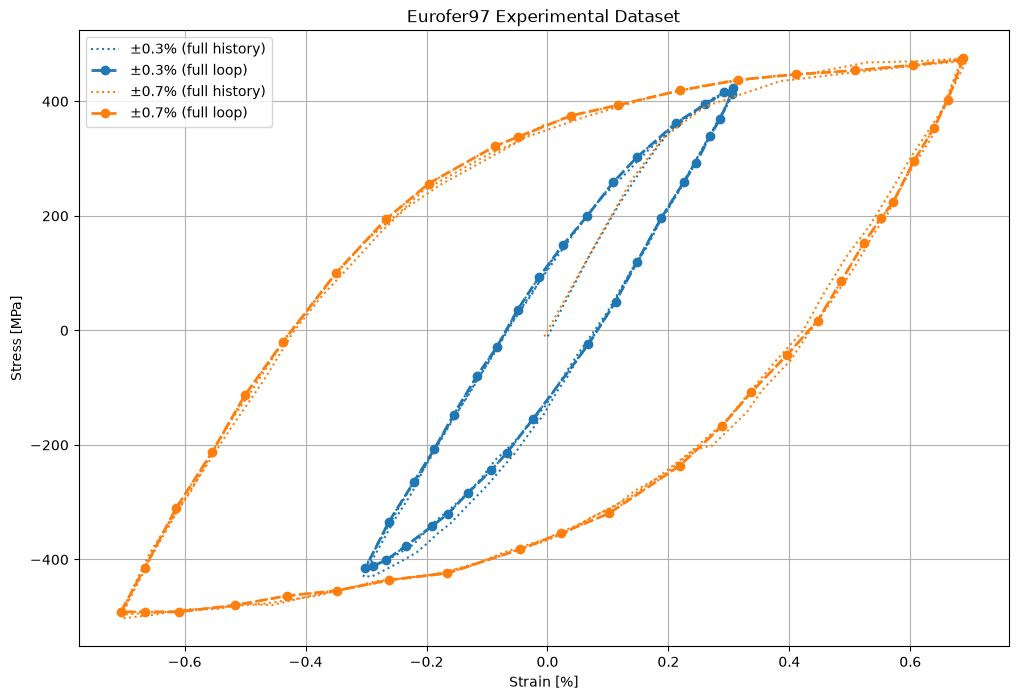

In [5]:
path = "cyclic_data"
amp_labels = ["0.3", "0.7"]

raw_strain = {}
raw_stress = {}
loop_strain = {}
loop_stress = {}
loop_neg_peak = {}

compare_cycle = 1
n_cycles = 3


def strain_reversals(strain):
    """Indices where the strain path changes direction."""
    s = torch.sign(strain.diff())
    return (torch.nonzero(s[1:] != s[:-1]).flatten() + 1).tolist()


for amp in amp_labels:
    (filenames,) = [
        f for f in os.listdir(path) if f.startswith("Eurofer97") and amp in f and f.endswith(".csv")
    ]
    df = pd.read_csv(os.path.join(path, filenames))

    strain = (
        torch.tensor(df["x"].values, device=device) * 1.0e-2
    )  # convert from percent to real strain
    stress = torch.tensor(df["y"].values, device=device)
    raw_strain[amp] = strain
    raw_stress[amp] = stress

    rev = strain_reversals(raw_strain[amp])
    tens_peaks = [i for i in rev if raw_strain[amp][i] > 0]
    assert len(tens_peaks) == n_cycles, f"{amp}%: tensile peaks at {tens_peaks}"
    i0, i1 = tens_peaks[compare_cycle], tens_peaks[compare_cycle + 1]
    loop_strain[amp] = raw_strain[amp][i0 : i1 + 1]
    loop_stress[amp] = raw_stress[amp][i0 : i1 + 1]
    loop_neg_peak[amp] = int(torch.argmin(loop_strain[amp]))
    print(
        f"{amp}%: {len(strain)} points, loop uses {len(loop_strain[amp])} "
        f"(strain {loop_strain[amp].min() * 100:.3f}% to {loop_strain[amp].max() * 100:.3f}%)"
    )
plt.figure(figsize=(12, 8))
for i, amp in enumerate(amp_labels):
    plt.plot(
        raw_strain[amp].cpu().numpy() * 100,
        raw_stress[amp].cpu().numpy(),
        ":",
        color=f"C{i}",
        label=rf"$\pm${amp}% (full history)",
    )
    plt.plot(
        loop_strain[amp].cpu().numpy() * 100,
        loop_stress[amp].cpu().numpy(),
        "--o",
        lw=2,
        color=f"C{i}",
        label=rf"$\pm${amp}% (full loop)",
    )
plt.xlabel("Strain [%]")
plt.ylabel("Stress [MPa]")
plt.title("Eurofer97 Experimental Dataset")
plt.legend()
plt.grid()

In [6]:
temperature_K = 300.0 + 273.15
strain_rate = 0.001
amplitudes = [0.003, 0.007]
loss_weights = [1.0, 1.0]
points_per_cycle = 80
nbatch = len(amp_labels)
assert points_per_cycle % 4 == 0

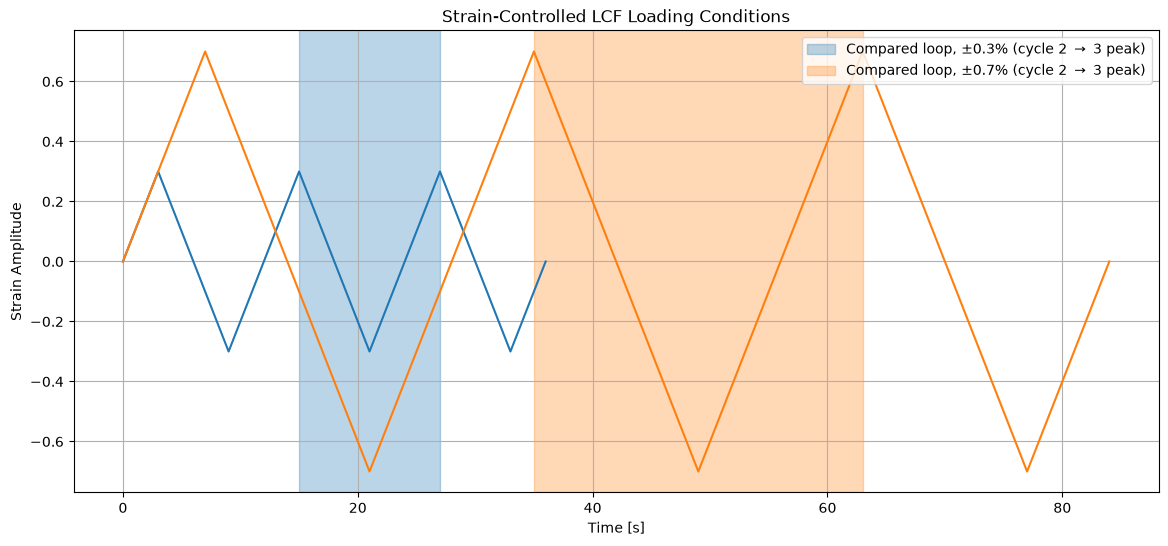


--- Full Input Tensors ---
time: torch.Size([241, 2])
temperature: torch.Size([241, 2])
loading: torch.Size([241, 2, 6])


In [7]:
q = points_per_cycle // 4


def one_cycle(amp):
    """One fully reversed triangle cycle 0 -> +amp -> -amp -> 0 at constant |strain rate|."""
    return torch.cat(
        [
            torch.linspace(0.0, amp, q + 1, device=device)[1:],
            torch.linspace(amp, -amp, 2 * q + 1, device=device)[1:],
            torch.linspace(-amp, 0.0, q + 1, device=device)[1:],
        ]
    )


strain_history = torch.stack(
    [torch.cat([torch.zeros(1, device=device), one_cycle(a).repeat(n_cycles)]) for a in amplitudes],
    dim=1,
)

time = (
    torch.cat([torch.zeros(1, nbatch, device=device), strain_history.diff(dim=0).abs()]).cumsum(0)
    / strain_rate
)

ntime = strain_history.shape[0]
temperature = torch.full_like(time, temperature_K)
loading = torch.zeros((ntime, nbatch, 6), device=device)
loading[..., 0] = strain_history

i_peak = 1 + compare_cycle * points_per_cycle + q - 1
loop_idx = torch.arange(i_peak, i_peak + points_per_cycle + 1, device=device)

plt.figure(figsize=(14, 6))

for j, (amp, label) in enumerate(zip(amplitudes, amp_labels)):
    t = time[:, j].cpu().numpy()
    plt.plot(t, strain_history[:, j].cpu().numpy() * 100)
    plt.axvspan(
        t[loop_idx[0]],
        t[loop_idx[-1]],
        color=f"C{j}",
        alpha=0.3,
        label=rf"Compared loop, $\pm${label}% (cycle {compare_cycle + 1} $\rightarrow$ {compare_cycle + 2} peak)",
    )

plt.xlabel("Time [s]")
plt.ylabel("Strain Amplitude")
plt.title("Strain-Controlled LCF Loading Conditions")
plt.legend()
plt.grid()
plt.show()

print(
    f"\n--- Full Input Tensors ---\ntime: {time.shape}\ntemperature: {temperature.shape}\nloading: {loading.shape}"
)

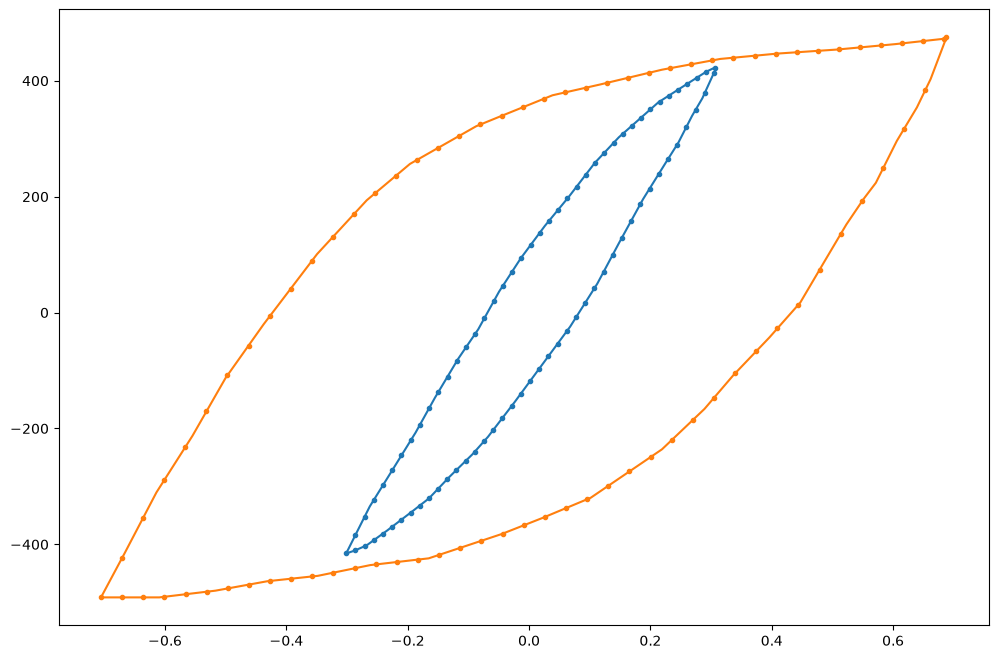

In [8]:
def resample_branch(eps, sig, n):
    """Resample a monotonic branch onto n points evenly spaced in strain path."""
    s = torch.cat([eps.new_zeros(1), eps.diff().abs()]).cumsum(0)
    u = (s / s[-1]).cpu().numpy()
    un = np.linspace(0.0, 1.0, n)
    return (
        torch.tensor(np.interp(un, u, eps.cpu().numpy()), device=device),
        torch.tensor(np.interp(un, u, sig.cpu().numpy()), device=device),
    )


target_stress = torch.zeros(len(loop_idx), nbatch, 1, device=device)
target_strain = torch.zeros(len(loop_idx), nbatch, 1, device=device)

plt.figure(figsize=(12, 8))
for j, amp in enumerate(amp_labels):
    eps, sig, k = loop_strain[amp], loop_stress[amp], loop_neg_peak[amp]
    e_dn, s_dn = resample_branch(eps[: k + 1], sig[: k + 1], 2 * q + 1)
    e_up, s_up = resample_branch(eps[k:], sig[k:], 2 * q + 1)
    target_strain[:, j, 0] = torch.cat([e_dn, e_up[1:]])
    target_stress[:, j, 0] = torch.cat([s_dn, s_up[1:]])
    plt.plot(loop_strain[amp].cpu() * 100, loop_stress[amp].cpu(), "-", color=f"C{j}")
    plt.plot(
        target_strain[:, j, 0].cpu() * 100, target_stress[:, j, 0].cpu(), "o", ms=3, color=f"C{j}"
    )

In [9]:
initial_params = {}
print("--- Before Reparameterization ---")
with torch.no_grad():
    for n, p in model.named_parameters():
        initial_params[n] = p.data.detach().clone()
        print(f"{n}: {p.data}, {p.shape}\n")

--- Before Reparameterization ---
discrete_equations.v_disl_B_k: 6.6e-11, torch.Size([])

discrete_equations.v_disl_T_0: 1530.42175, torch.Size([])

discrete_equations.v_disl_p: 0.65, torch.Size([])

discrete_equations.v_disl_q: 1.7, torch.Size([])

discrete_equations.v_disl_H_0: 2.17, torch.Size([])

discrete_equations.X1rate_C: 7000.0, torch.Size([])

discrete_equations.X1rate_g: 600.0, torch.Size([])

discrete_equations.rho_m_rate_k1: 78000.0, torch.Size([])

discrete_equations.rho_m_rate_k2_0: 6750.0, torch.Size([])



In [10]:
class LogRangeRescale(reparametrization.RangeRescale):
    """Map [0, 1] to [lb, ub] in log space, so an Adam step is a relative change."""

    def __init__(
        self,
        lb: torch.Tensor | float,
        ub: torch.Tensor | float,
        clamp: bool = True,
    ) -> None:
        super().__init__(lb, ub, clamp)
        self.lb = math.log(lb)
        self.ub = math.log(ub)
        self.clamp = clamp

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        if self.clamp:
            X = torch.clamp(X, 0, 1)

        return torch.exp(X * (self.ub - self.lb) + self.lb)

    def reverse(self, X: torch.Tensor) -> torch.Tensor:
        Y = (torch.log(X) - self.lb) / (self.ub - self.lb)

        if self.clamp:
            return torch.clamp(Y, 0, 1)

        return Y

In [11]:
Bk_scaler = LogRangeRescale(
    torch.tensor(1.0e-12, device=device), torch.tensor(1.0e-9, device=device)
)  # MPa*s
T_0_scaler = reparametrization.RangeRescale(
    torch.tensor(100.0, device=device), torch.tensor(5000.0, device=device)
)  # K
p_scaler = LogRangeRescale(torch.tensor(0.01, device=device), torch.tensor(10.0, device=device))
q_scaler = LogRangeRescale(torch.tensor(0.01, device=device), torch.tensor(10.0, device=device))
H0_scaler = reparametrization.RangeRescale(
    torch.tensor(0.1, device=device), torch.tensor(10.0, device=device)
)  # eV
X1C_scaler = LogRangeRescale(
    torch.tensor(100.0, device=device), torch.tensor(1.0e6, device=device)
)  # MPa
X1g_scaler = LogRangeRescale(torch.tensor(0.1, device=device), torch.tensor(1.0e4, device=device))
k1_scaler = LogRangeRescale(
    torch.tensor(100.0, device=device), torch.tensor(1.0e7, device=device)
)  # um^-1
k2_0_scaler = LogRangeRescale(
    torch.tensor(0.0001, device=device), torch.tensor(1.0e6, device=device)
)

model_reparameterizer = reparametrization.Reparameterizer(
    {
        "discrete_equations.v_disl_B_k": Bk_scaler,
        "discrete_equations.v_disl_T_0": T_0_scaler,
        "discrete_equations.v_disl_p": p_scaler,
        "discrete_equations.v_disl_q": q_scaler,
        "discrete_equations.v_disl_H_0": H0_scaler,
        "discrete_equations.X1rate_C": X1C_scaler,
        "discrete_equations.X1rate_g": X1g_scaler,
        "discrete_equations.rho_m_rate_k1": k1_scaler,
        "discrete_equations.rho_m_rate_k2_0": k2_0_scaler,
    },
    error_not_provided=True,
)
model_reparameterizer(model)
print(f"--- After Reparameterization ---")
initial_params_reparam = {}
for n, p in model.named_parameters():
    initial_params_reparam[n] = p.data.detach().clone()
    print(f"{n}: {p.data}, requires_grad={p.requires_grad}")

--- After Reparameterization ---
discrete_equations.parametrizations.v_disl_B_k.original: 0.6065146451806226, requires_grad=True
discrete_equations.parametrizations.v_disl_T_0.original: 0.291922806122449, requires_grad=True
discrete_equations.parametrizations.v_disl_p.original: 0.6043044522142852, requires_grad=True
discrete_equations.parametrizations.v_disl_q.original: 0.743482973792758, requires_grad=True
discrete_equations.parametrizations.v_disl_H_0.original: 0.20909090909090908, requires_grad=True
discrete_equations.parametrizations.X1rate_C.original: 0.4612745100035642, requires_grad=True
discrete_equations.parametrizations.X1rate_g.original: 0.7556302500767287, requires_grad=True
discrete_equations.parametrizations.rho_m_rate_k1.original: 0.5784189205380961, requires_grad=True
discrete_equations.parametrizations.rho_m_rate_k2_0.original: 0.7829303772831027, requires_grad=True


In [12]:
prior_cov = 0.05
prior_noise_scale = 10.0

mapper = stochastic.MapNormal(prior_cov)
hsmodel = stochastic.HierarchicalStatisticalModel(
    model, mapper, torch.tensor(prior_noise_scale, device=device)
)

In [13]:
nreps = 10
predict = Predictive(hsmodel, num_samples=nreps)
with torch.no_grad():
    untrained = predict(loading, time, temperature)["obs"]

/tmp/ipykernel_29012/3340930528.py:55: UserWarning: pyzag lowered torch._functorch.config.donated_buffer's default to False process-wide. AOTAutograd 'donated buffers' (torch>=2.12) are incompatible with pyzag's retain_graph=True adjoint over torch.compile'd models, which otherwise raises 'compiled with non-empty donated buffers'. To keep donated buffers enabled, restore torch._functorch.config._config['donated_buffer'].default = True -- compiled models differentiated through the adjoint will then error.
  solver = nonlinear.RecursiveNonlinearEquationSolver(
/home/quantumsurfer/anaconda3/envs/neml2/lib/python3.12/site-packages/pyzag/chunktime.py:135: UserWarning: Implicit solve did not succeed.  Results may be inaccurate...
  warnings.warn(


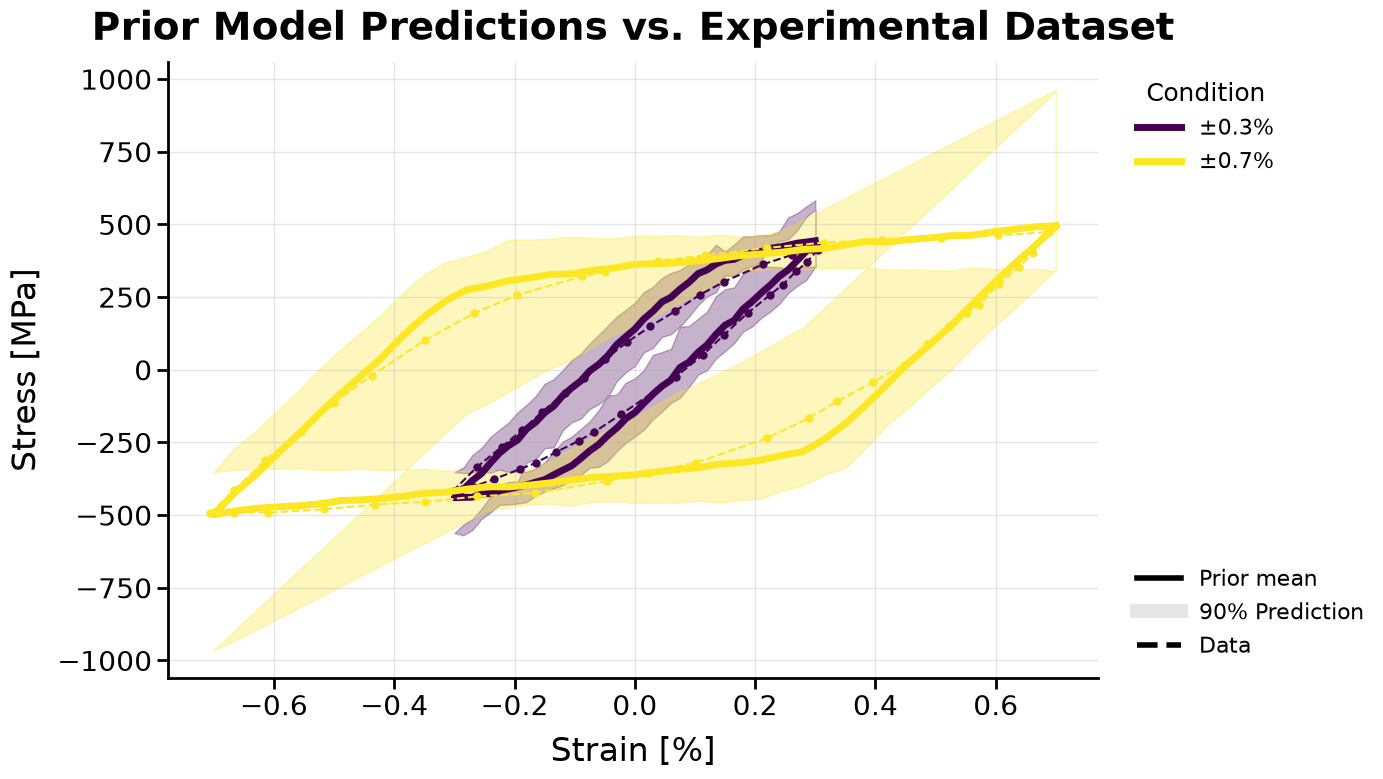

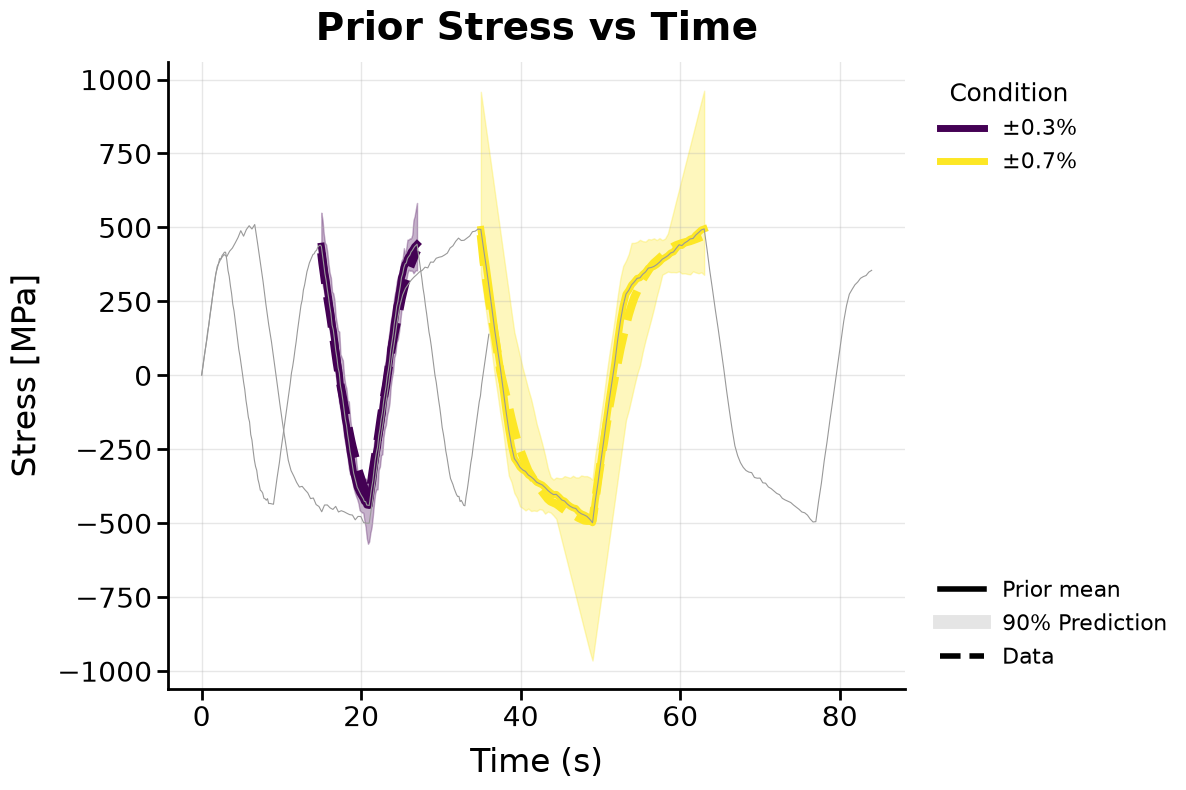

In [25]:
color = mpl.cm.viridis(np.linspace(0, 1, len(amp_labels)))
fig, ax = plt.subplots(figsize=(12, 8))

for j, label in enumerate(amp_labels):
    idx = loop_idx.cpu()
    prior_loop_stress = untrained[:, idx, j, 0]
    eps = loading[idx, j, 0].cpu().numpy() * 100
    ax.plot(
        eps,
        prior_loop_stress.mean(axis=0).cpu(),
        color=color[j],
        lw=5,
    )
    lo, hi = torch.quantile(prior_loop_stress, torch.tensor([0.05, 0.95], device=device), dim=0)
    ax.fill_between(
        eps,
        lo.cpu(),
        hi.cpu(),
        color=color[j],
        alpha=0.3,
    )
    ax.plot(
        loop_strain[label].cpu().numpy() * 100,
        loop_stress[label].cpu().numpy(),
        "--o",
        ms=5,
        color=color[j],
    )
# Legend: one colored entry per test condition, plus line-style key for Model vs Data
cond_handles = [
    Line2D(
        [0],
        [0],
        color=color[j],
        lw=5,
        label=rf"$\pm${amp}%",
    )
    for j, amp in enumerate(amp_labels)
]
style_handles = [
    Line2D([0], [0], color="k", lw=4, label="Prior mean"),
    Line2D([], [], color="0.8", alpha=0.5, lw=10, label="90% Prediction"),
    Line2D([0], [0], color="k", lw=4, ls="--", label="Data"),
]
leg_cond = ax.legend(
    handles=cond_handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    fontsize=16,
    title="Condition",
    title_fontsize=18,
    frameon=False,
)
ax.add_artist(leg_cond)
ax.legend(
    handles=style_handles,
    loc="lower left",
    bbox_to_anchor=(1.02, 0.0),
    fontsize=16,
    frameon=False,
)

ax.set_xlabel("Strain [%]", fontsize=24, labelpad=10)
ax.set_ylabel("Stress [MPa]", fontsize=24, labelpad=10)
ax.set_title(
    "Prior Model Predictions vs. Experimental Dataset", fontsize=28, fontweight="bold", pad=16
)
ax.tick_params(axis="both", which="major", labelsize=20, width=2, length=8)
ax.grid(True, alpha=0.3, lw=1)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
for spine in ("left", "bottom"):
    ax.spines[spine].set_linewidth(2)

t = time.cpu().numpy()
fig, ax1 = plt.subplots(figsize=(12, 8))
for j, label in enumerate(amp_labels):
    idx = loop_idx.cpu()
    prior_loop_stress = untrained[:, idx, j, 0]
    lo, hi = torch.quantile(prior_loop_stress, torch.tensor([0.05, 0.95], device=device), dim=0)
    ax1.plot(t[idx, j], prior_loop_stress.mean(dim=0).detach().cpu().numpy(), color=color[j], lw=5)
    ax1.fill_between(t[idx, j], lo.cpu().numpy(), hi.cpu().numpy(), color=color[j], alpha=0.3)
    ax1.plot(t[idx, j], target_stress[:, j, 0].cpu().numpy(), "--", color=color[j], lw=6)
    ax1.plot(t[:, j], untrained[:, :, j, 0].mean(dim=0).cpu().numpy(), color="0.6", lw=0.8)
leg_cond = ax1.legend(
    handles=cond_handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    fontsize=16,
    title="Condition",
    title_fontsize=18,
    frameon=False,
)
ax1.add_artist(leg_cond)
ax1.legend(
    handles=style_handles,
    loc="lower left",
    bbox_to_anchor=(1.02, 0.0),
    fontsize=16,
    frameon=False,
)
ax1.set_xlabel("Time (s)", fontsize=24, labelpad=10)
ax1.set_ylabel("Stress [MPa]", fontsize=24, labelpad=10)
ax1.set_title("Prior Stress vs Time", fontsize=28, fontweight="bold", pad=16)
ax1.tick_params(axis="both", which="major", labelsize=20, width=2, length=8)
ax1.grid(True, alpha=0.3, lw=1)
for spine in ("top", "right"):
    ax1.spines[spine].set_visible(False)
for spine in ("left", "bottom"):
    ax1.spines[spine].set_linewidth(2)
plt.tight_layout()
plt.show()

In [27]:
from pyro.poutine.messenger import Messenger


class ObsSiteMask(Messenger):
    def __init__(self, mask, scale=None, site="obs"):
        super().__init__()
        self.mask, self.scale, self.site = mask, scale, site

    def _process_message(self, msg):
        if msg.get("name") != self.site:
            return
        msg["mask"] = self.mask if msg.get("mask") is None else msg.get("mask") & self.mask
        if self.scale is not None:
            msg["scale"] = self.scale * msg.get("scale", 1.0)


obs_stress = torch.zeros(ntime, nbatch, 1, device=device)
obs_mask = torch.zeros(ntime, nbatch, dtype=torch.bool, device=device)
obs_weight = torch.zeros(ntime, nbatch, device=device)
for j in range(len(amp_labels)):
    idx = loop_idx.cpu()
    obs_stress[idx, 0, 0] = target_stress[:, j, 0]
    obs_mask[idx, 0] = True
    obs_weight[idx, 0] = loss_weights[j]

print(f"Observed steps: {int(obs_mask.sum())} of {ntime}")

Observed steps: 81 of 241


Loss:: :   0%|          |0/500W1028 16:52:55.040000 29012 site-packages/torch/_dynamo/convert_frame.py:1853] [17/8] torch._dynamo hit config.recompile_limit (8)
W1028 16:52:55.040000 29012 site-packages/torch/_dynamo/convert_frame.py:1853] [17/8]    function: 'forward' (/home/quantumsurfer/neml2/neml2/models/common/LinearCombination.py:104)
W1028 16:52:55.040000 29012 site-packages/torch/_dynamo/convert_frame.py:1853] [17/8]    last reason: 17/7: KeyError on v['back_stress']
W1028 16:52:55.040000 29012 site-packages/torch/_dynamo/convert_frame.py:1853] [17/8] To log all recompilation reasons, use TORCH_LOGS="recompiles".
W1028 16:52:55.040000 29012 site-packages/torch/_dynamo/convert_frame.py:1853] [17/8] To diagnose recompilation issues, see https://docs.pytorch.org/docs/main/user_guide/torch_compiler/compile/programming_model.recompilation.html
W1028 16:53:49.466000 29012 site-packages/torch/_dynamo/convert_frame.py:1853] [28/8] torch._dynamo hit config.recompile_limit (8)
W1028 16:5

Restored iteration 499, loss 9.191e+03


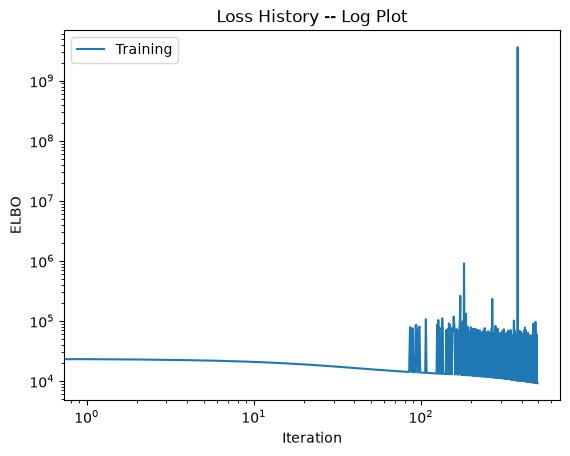

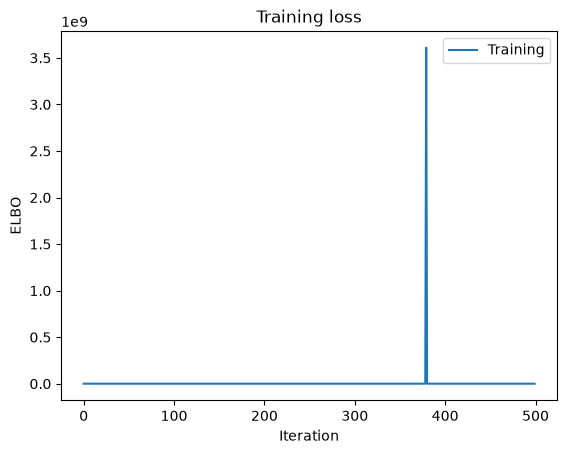

In [28]:
guide = AutoDelta(hsmodel)
lr = 5e-4
niter = 500
num_samples = 1

optimizer = ClippedAdam({"lr": lr})
loss = Trace_ELBO(num_particles=num_samples)
svi = SVI(hsmodel, guide, optimizer, loss=loss)

titer = tqdm.tqdm(
    range(niter),
    bar_format="{desc}: {percentage:3.0f}%|{bar}|{n_fmt}/{total_fmt}{postfix}",
)
titer.set_description("Loss:")
loss_history = []
best_loss = float("inf")
best_state: dict | None = None
best_iter = -1
n_fail = 0

for i in titer:
    try:
        with ObsSiteMask(obs_mask, scale=obs_weight):
            closs = svi.step(loading, time, temperature, results=obs_stress)
    except RuntimeError as e:
        if "Implicit solve did not succeed" not in str(e):
            raise
        n_fail += 1
        titer.set_postfix(fails=n_fail, best=f"{best_loss:.2e}")
        continue

    if not math.isfinite(closs):
        n_fail += 1
        continue

    loss_history.append(closs)
    titer.set_description("Loss: %3.2e" % closs)

    if closs < best_loss:
        best_loss, best_iter = closs, i
        best_state = copy.deepcopy(pyro.get_param_store().get_state())

if best_state is None:
    raise RuntimeError("No successful training step; nothing to restore.")

pyro.get_param_store().set_state(best_state)
print(f"Restored iteration {best_iter}, loss {best_loss:.3e}")

plt.figure()
plt.loglog(loss_history, label="Training")
plt.xlabel("Iteration")
plt.ylabel("ELBO")
plt.legend(loc="best")
plt.title("Loss History -- Log Plot")

plt.figure()
plt.plot(loss_history, label="Training")
plt.xlabel("Iteration")
plt.ylabel("ELBO")
plt.legend(loc="best")
plt.title("Training loss")
plt.show()

In [29]:
nreps = 10
predict = Predictive(hsmodel, guide=guide, num_samples=nreps)
with torch.no_grad():
    trained = predict(loading, time, temperature)["obs"]

/home/quantumsurfer/anaconda3/envs/neml2/lib/python3.12/site-packages/pyzag/chunktime.py:135: UserWarning: Implicit solve did not succeed.  Results may be inaccurate...
  warnings.warn(


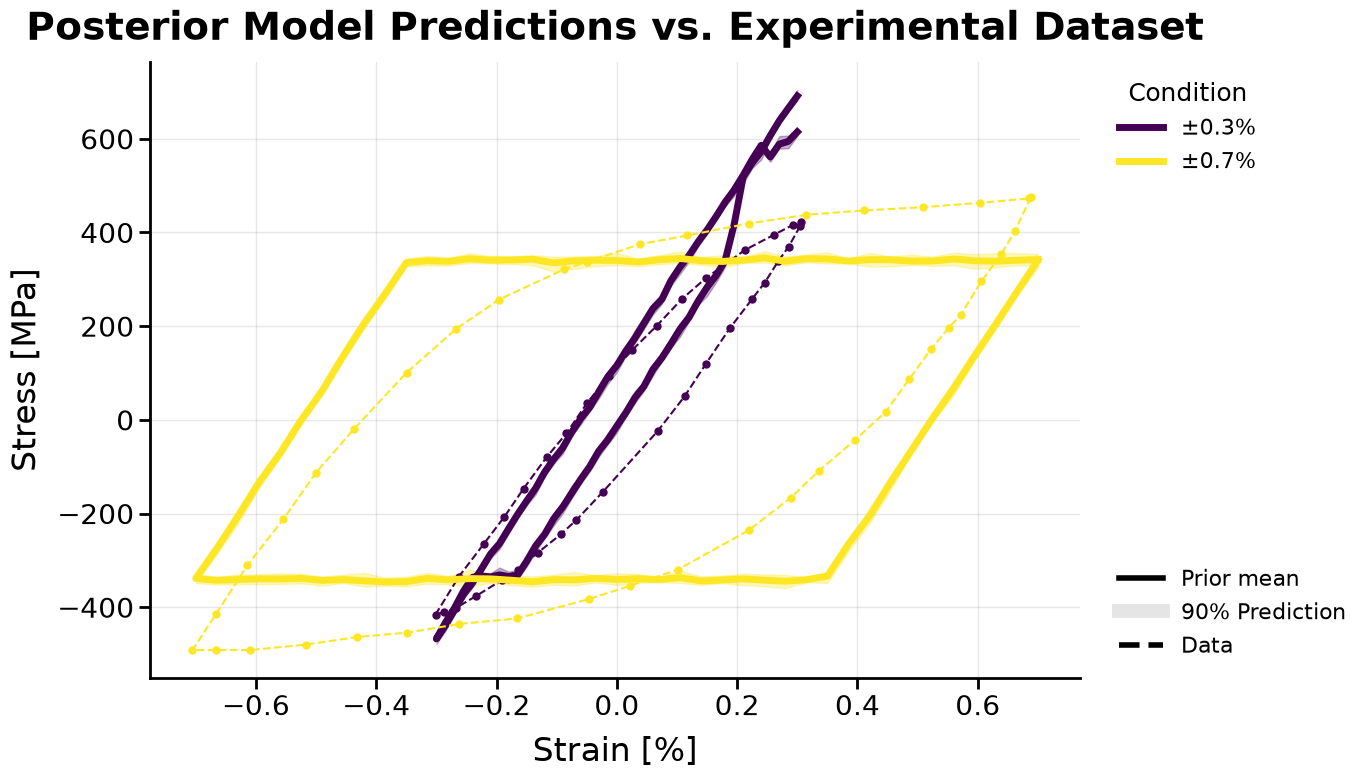

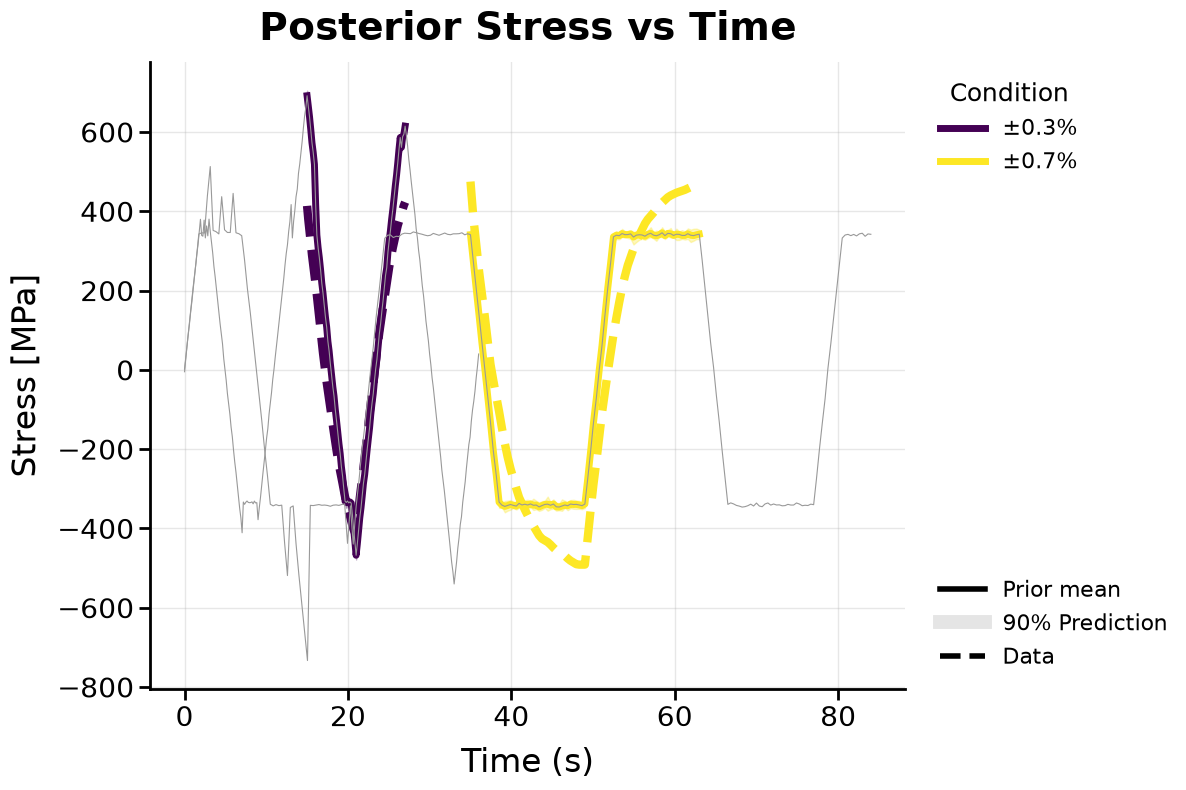

In [30]:
color = mpl.cm.viridis(np.linspace(0, 1, len(amp_labels)))
fig, ax = plt.subplots(figsize=(12, 8))

for j, label in enumerate(amp_labels):
    idx = loop_idx.cpu()
    post_loop_stress = trained[:, idx, j, 0]
    eps = loading[idx, j, 0].cpu().numpy() * 100
    ax.plot(
        eps,
        post_loop_stress.mean(axis=0).cpu(),
        color=color[j],
        lw=5,
    )
    lo, hi = torch.quantile(post_loop_stress, torch.tensor([0.05, 0.95], device=device), dim=0)
    ax.fill_between(
        eps,
        lo.cpu(),
        hi.cpu(),
        color=color[j],
        alpha=0.3,
    )
    ax.plot(
        loop_strain[label].cpu().numpy() * 100,
        loop_stress[label].cpu().numpy(),
        "--o",
        ms=5,
        color=color[j],
    )
# Legend: one colored entry per test condition, plus line-style key for Model vs Data
cond_handles = [
    Line2D(
        [0],
        [0],
        color=color[j],
        lw=5,
        label=rf"$\pm${amp}%",
    )
    for j, amp in enumerate(amp_labels)
]
style_handles = [
    Line2D([0], [0], color="k", lw=4, label="Prior mean"),
    Line2D([], [], color="0.8", alpha=0.5, lw=10, label="90% Prediction"),
    Line2D([0], [0], color="k", lw=4, ls="--", label="Data"),
]
leg_cond = ax.legend(
    handles=cond_handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    fontsize=16,
    title="Condition",
    title_fontsize=18,
    frameon=False,
)
ax.add_artist(leg_cond)
ax.legend(
    handles=style_handles,
    loc="lower left",
    bbox_to_anchor=(1.02, 0.0),
    fontsize=16,
    frameon=False,
)

ax.set_xlabel("Strain [%]", fontsize=24, labelpad=10)
ax.set_ylabel("Stress [MPa]", fontsize=24, labelpad=10)
ax.set_title(
    "Posterior Model Predictions vs. Experimental Dataset", fontsize=28, fontweight="bold", pad=16
)
ax.tick_params(axis="both", which="major", labelsize=20, width=2, length=8)
ax.grid(True, alpha=0.3, lw=1)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
for spine in ("left", "bottom"):
    ax.spines[spine].set_linewidth(2)

t = time.cpu().numpy()
fig, ax1 = plt.subplots(figsize=(12, 8))
for j, label in enumerate(amp_labels):
    idx = loop_idx.cpu()
    post_loop_stress = trained[:, idx, j, 0]
    lo, hi = torch.quantile(post_loop_stress, torch.tensor([0.05, 0.95], device=device), dim=0)
    ax1.plot(t[idx, j], post_loop_stress.mean(dim=0).detach().cpu().numpy(), color=color[j], lw=5)
    ax1.fill_between(t[idx, j], lo.cpu().numpy(), hi.cpu().numpy(), color=color[j], alpha=0.3)
    ax1.plot(t[idx, j], target_stress[:, j, 0].cpu().numpy(), "--", color=color[j], lw=6)
    ax1.plot(t[:, j], trained[:, :, j, 0].mean(dim=0).cpu().numpy(), color="0.6", lw=0.8)
leg_cond = ax1.legend(
    handles=cond_handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    fontsize=16,
    title="Condition",
    title_fontsize=18,
    frameon=False,
)
ax1.add_artist(leg_cond)
ax1.legend(
    handles=style_handles,
    loc="lower left",
    bbox_to_anchor=(1.02, 0.0),
    fontsize=16,
    frameon=False,
)
ax1.set_xlabel("Time (s)", fontsize=24, labelpad=10)
ax1.set_ylabel("Stress [MPa]", fontsize=24, labelpad=10)
ax1.set_title("Posterior Stress vs Time", fontsize=28, fontweight="bold", pad=16)
ax1.tick_params(axis="both", which="major", labelsize=20, width=2, length=8)
ax1.grid(True, alpha=0.3, lw=1)
for spine in ("top", "right"):
    ax1.spines[spine].set_visible(False)
for spine in ("left", "bottom"):
    ax1.spines[spine].set_linewidth(2)
plt.tight_layout()
plt.show()

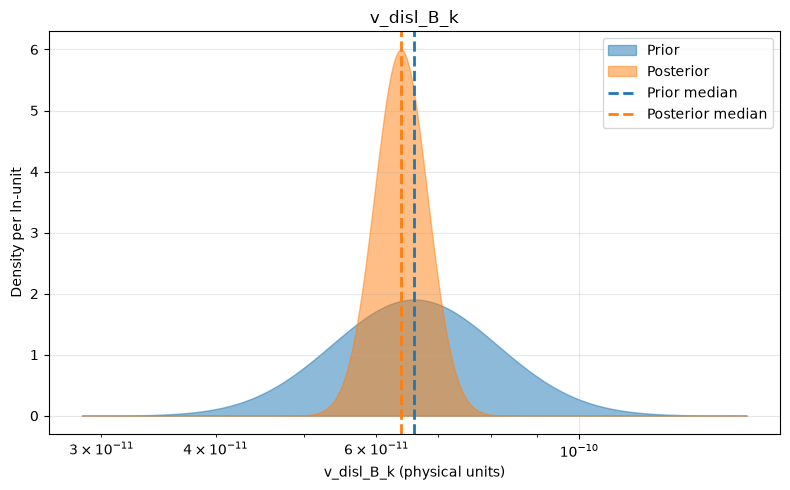

v_disl_B_k: loc = 6.600e-11, scale = 1.233
v_disl_B_k: loc = 6.380e-11, scale = 1.069


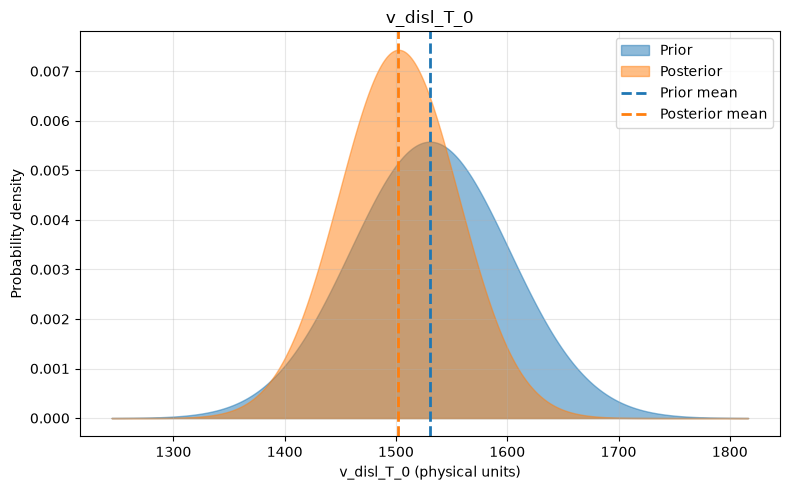

v_disl_T_0: loc = 1530.422, scale = 71.521
v_disl_T_0: loc = 1502.276, scale = 53.675


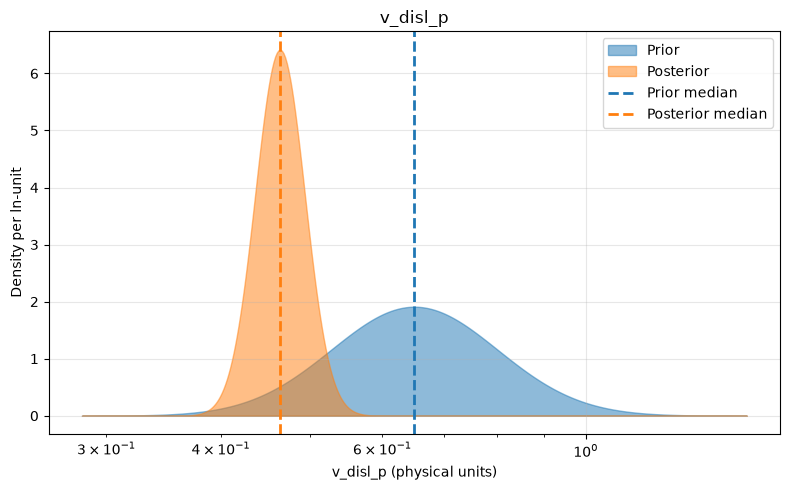

v_disl_p: loc = 0.650, scale = 1.232
v_disl_p: loc = 0.464, scale = 1.064


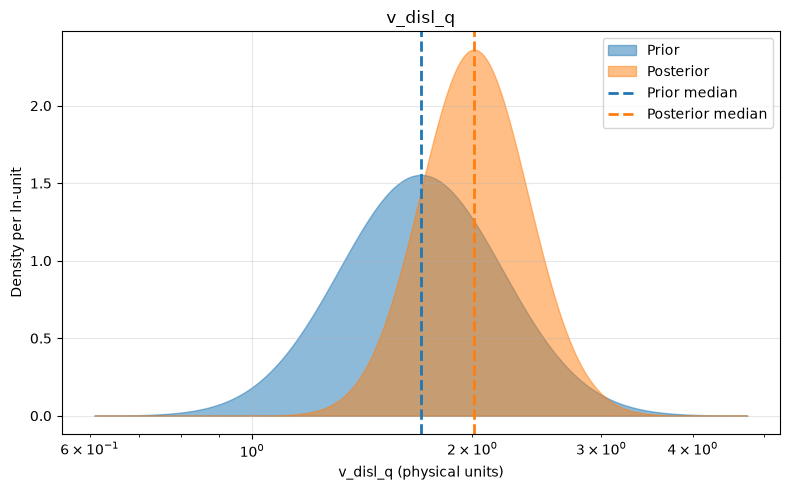

v_disl_q: loc = 1.700, scale = 1.293
v_disl_q: loc = 2.010, scale = 1.184


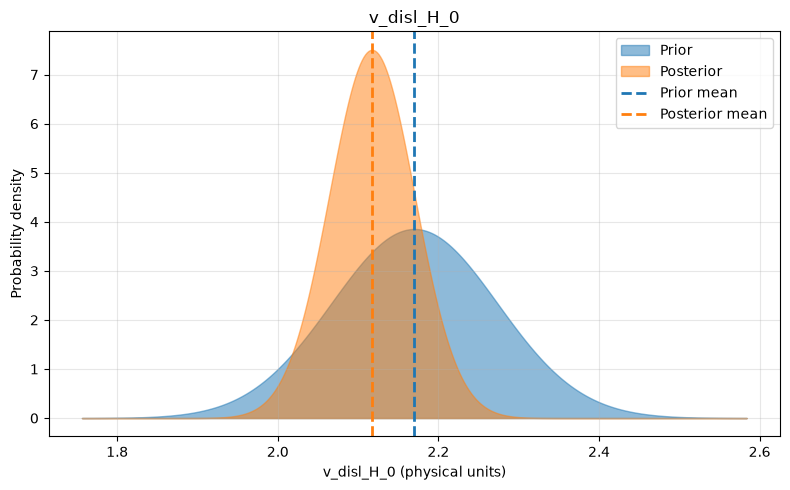

v_disl_H_0: loc = 2.170, scale = 0.103
v_disl_H_0: loc = 2.117, scale = 0.053


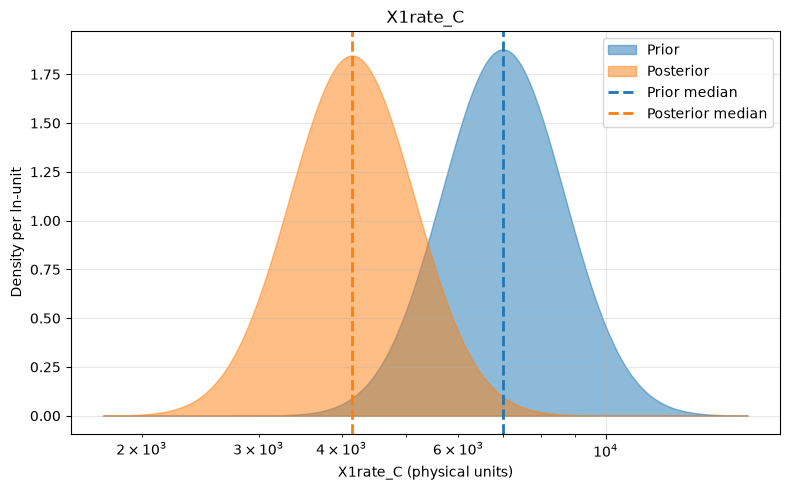

X1rate_C: loc = 7000.000, scale = 1.237
X1rate_C: loc = 4148.374, scale = 1.241


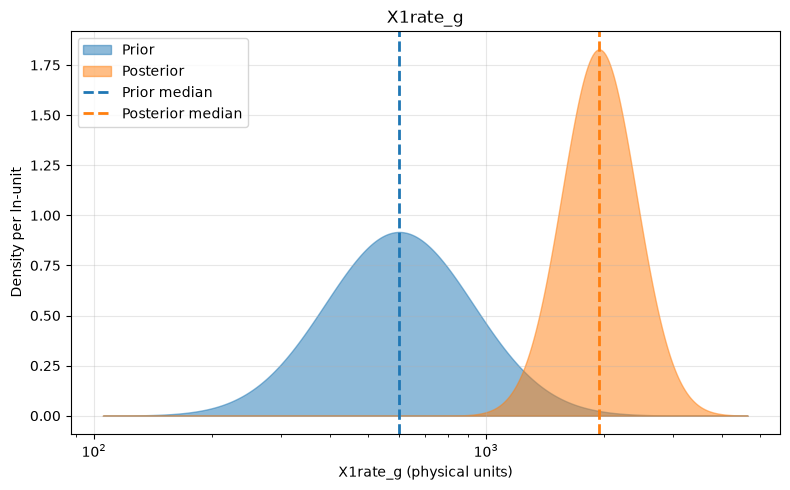

X1rate_g: loc = 600.000, scale = 1.545
X1rate_g: loc = 1942.338, scale = 1.244


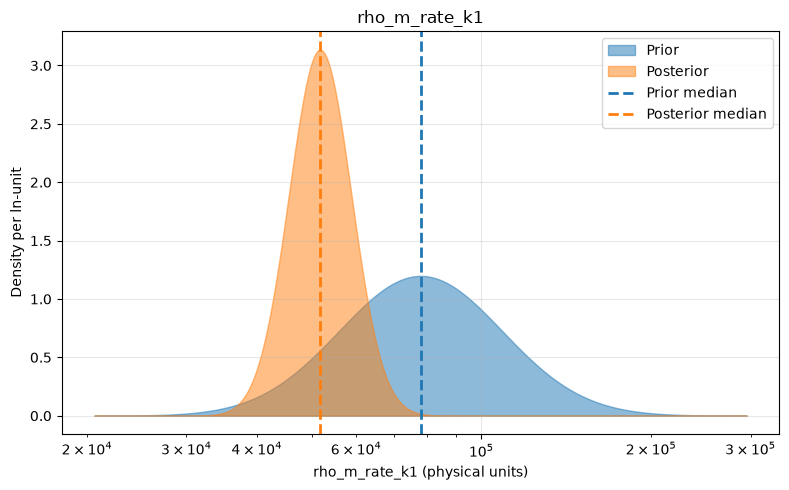

rho_m_rate_k1: loc = 78000.000, scale = 1.395
rho_m_rate_k1: loc = 51775.007, scale = 1.136


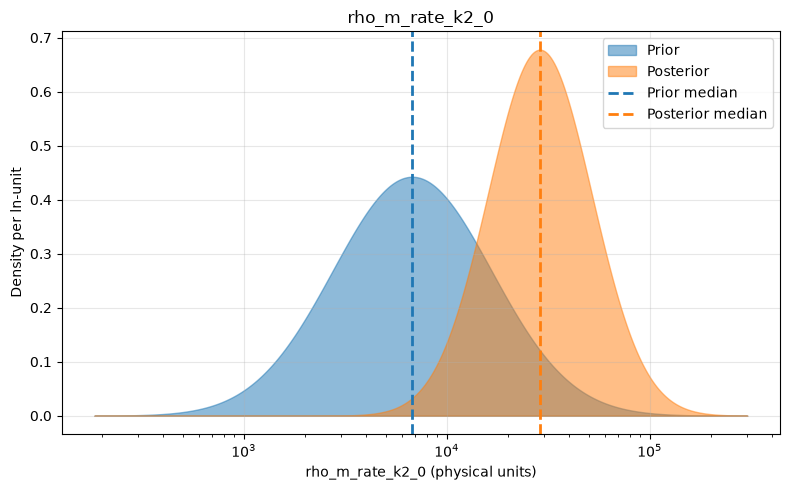

rho_m_rate_k2_0: loc = 6750.000, scale = 2.463
rho_m_rate_k2_0: loc = 28760.782, scale = 1.801


In [31]:
def scaled_to_physical(scaler, mu, sigma):
    lb, ub = float(scaler.lb), float(scaler.ub)
    return lb + float(mu) * (ub - lb), float(sigma) * abs(ub - lb)


for _, _, n in hsmodel.bot:
    key = ".".join(n.split(".")[i] for i in [0, 2])
    scaler = model_reparameterizer.map_dict[key]
    param_name = key.split(".")[-1]
    is_log = isinstance(scaler, LogRangeRescale)

    # Scaled-space (z) normals
    prior_loc = initial_params_reparam[n]
    prior_scale = prior_cov * prior_loc.abs()
    post_loc = pyro.param(f"AutoDelta.{n}_loc").detach()
    post_scale = pyro.param(f"AutoDelta.{n}_scale").detach()

    # Physical-space normals (in u = theta or ln(theta))
    mu_prior, sigma_prior = scaled_to_physical(scaler, prior_loc, prior_scale)
    mu_post, sigma_post = scaled_to_physical(scaler, post_loc, post_scale)

    # Common grid covering both distribution, limited to the clamp bounds [lb, ub]
    lo = max(min(mu_prior - 4 * sigma_prior, mu_post - 4 * sigma_post), float(scaler.lb))
    hi = min(max(mu_prior + 4 * sigma_prior, mu_post + 4 * sigma_post), float(scaler.ub))
    u = torch.linspace(lo, hi, 400, device=device)

    y_prior = dist.Normal(mu_prior, sigma_prior).log_prob(u).exp()
    y_post = dist.Normal(mu_post, sigma_post).log_prob(u).exp()
    x = u.exp() if is_log else u
    to_x = math.exp if is_log else (lambda v: v)

    plt.figure(figsize=(8, 5))
    plt.fill_between(x.cpu(), y_prior.cpu(), alpha=0.5, color="C0", label="Prior")
    plt.fill_between(x.cpu(), y_post.cpu(), alpha=0.5, color="C1", label="Posterior")
    stat = "median" if is_log else "mean"
    plt.axvline(to_x(mu_prior), color="C0", ls="--", lw=2, label=f"Prior {stat}")
    plt.axvline(to_x(mu_post), color="C1", ls="--", lw=2, label=f"Posterior {stat}")

    if is_log:
        plt.xscale("log")
    plt.xlabel(f"{param_name} (physical units)")
    plt.ylabel("Density per ln-unit" if is_log else "Probability density")
    plt.title(param_name)
    plt.legend(loc="best")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    if param_name == "v_disl_B_k":
        print(rf"{param_name}: loc = {to_x(mu_prior):.3e}, scale = {to_x(sigma_prior):.3f}")
        print(rf"{param_name}: loc = {to_x(mu_post):.3e}, scale = {to_x(sigma_post):.3f}")
    else:
        print(rf"{param_name}: loc = {to_x(mu_prior):.3f}, scale = {to_x(sigma_prior):.3f}")
        print(rf"{param_name}: loc = {to_x(mu_post):.3f}, scale = {to_x(sigma_post):.3f}")

In [32]:
import pickle, pathlib

out_dir = pathlib.Path("../figures/data")
out_dir.mkdir(parents=True, exist_ok=True)


def to_np(x):
    return x.detach().cpu().numpy()


q = torch.tensor([0.05, 0.95], device=device)

curves = []
for j, amp in enumerate(amp_labels):
    idx = loop_idx.cpu()
    samples = trained[:, idx, 0, 0]  # (nreps, ntime)
    prior_samples = untrained[:, idx, 0, 0]
    lo, hi = torch.quantile(samples, q, dim=0)
    plo, phi = torch.quantile(prior_samples, q, dim=0)
    curves.append(
        {
            "label": rf"$\pm${amp}%",
            "T": temperature_K,
            "rate": strain_rate,
            "amplitudes": amplitudes[j],
            "compare_cycle": compare_cycle,
            "loss_weight": loss_weights[j],
            "model_strain": to_np(loading[idx, j, 0]),
            "model_time": to_np(time[idx, j]),
            "model_stress_mean": to_np(samples.mean(dim=0)),
            "model_stress_lo": to_np(lo),  # 5% quantile
            "model_stress_hi": to_np(hi),  # 95% quantile
            "model_stress_samples": to_np(samples),
            "prior_stress_mean": to_np(prior_samples.mean(dim=0)),
            "prior_stress_lo": to_np(plo),
            "prior_stress_hi": to_np(phi),
            "exp_strain": to_np(loop_strain[amp]),
            "exp_stress": to_np(loop_stress[amp]),
            "exp_full_strain": to_np(raw_strain[amp]),
            "exp_full_stress": to_np(raw_stress[amp]),
            "exp_target_strain": to_np(target_strain[:, j, 0]),
            "exp_target_stress": to_np(target_stress[:, j, 0]),
        }
    )
# Full MST history, for the gray background trace
full = trained[:, :, 0, 0]
full_lo, full_hi = torch.quantile(full, q, dim=0)
background = {
    "time": to_np(time),
    "strain": to_np(strain_history),
    "stress_mean": to_np(full.mean(dim=0)),
    "stress_lo": to_np(full_lo),
    "stress_hi": to_np(full_hi),
    "prior_stress_mean": to_np(untrained[:, :, 0, 0].mean(dim=0)),
}

# Prior/posterior parameter distributions in physical space (same math as the last cell)
params = {}
for _, _, n in hsmodel.bot:
    key = ".".join(n.split(".")[k] for k in [0, 2])
    scaler = model_reparameterizer.map_dict[key]
    prior_loc = initial_params_reparam[n]
    mu_prior, sigma_prior = scaled_to_physical(scaler, prior_loc, prior_cov * prior_loc.abs())
    mu_post, sigma_post = scaled_to_physical(
        scaler,
        pyro.param(f"AutoDelta.{n}_loc").detach(),
        pyro.param(f"AutoDelta.{n}_scale").detach(),
    )
    params[key.split(".")[-1]] = {
        "is_log": is_log,
        "space": "ln" if is_log else "linear",
        "lb": float(scaler.lb),
        "ub": float(scaler.ub),
        "prior": (mu_prior, sigma_prior),
        "posterior": (mu_post, sigma_post),
    }

case = {
    "material": "eurofer97",
    "loading": "cyclic",
    "approach": "statistical",
    "quantiles": (0.05, 0.95),
    "nreps": nreps,
    "band_includes_noise": True,
    "noise_scale": pyro.param("AutoDelta.eps").item(),
    "curves": curves,
    "background": background,
    "params": params,
    "loss_history": [float(l) for l in loss_history],
    "best_iter": best_iter,
    "best_loss": best_loss,
    "n_fail": n_fail,
    "settings": {
        "prior_cov": prior_cov,
        "prior_noise_scale": prior_noise_scale,
        "lr": lr,
        "niter": niter,
        "temperature_K": temperature_K,
        "strain_rate": strain_rate,
        "amplitudes": amplitudes,
        "n_cycles": n_cycles,
        "compare_cycle": compare_cycle,
        "loss_weights": loss_weights,
        "points_per_cycle": points_per_cycle,
        "ntime": ntime,
        "nchunk": model.nchunk,
        "initial_rho_m": model.initial_rho_m,
    },
}

out_path = out_dir / "cyclic_eurofer97_statistical.pkl"
with open(out_path, "wb") as f:
    pickle.dump(case, f)
print(f"Saved {out_path.resolve()}")
print(f"Learned noise scale: {case['noise_scale']:.1f} MPa")

Saved /home/quantumsurfer/neml2/cmg_projects/figures/data/cyclic_eurofer97_statistical.pkl
Learned noise scale: 8.1 MPa
